# Chapitre 2 - Cours 1 : moindres carrés et plus proches voisins

Ce notebook couvre les sections 2.1 à 2.3 du livre. Nous y présentons les deux méthodes
de prédiction les plus simples :

- le **modèle linéaire** ajusté par moindres carrés : très structuré, stable, mais
  reposant sur une hypothèse forte (la linéarité) ;
- les **$k$ plus proches voisins** : presque aucune hypothèse, très flexible, mais
  instable.

Nous les comparons sur la simulation « mixture » du livre (figures 2.1 à 2.5), et nous
rencontrons pour la première fois le **classifieur de Bayes**, la règle optimale.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl.plotting import decision_grid
from esl import datasets
from esl import ch02_supervise as c2

set_style()
rng = np.random.RandomState(0)

## 1. Notations (section 2.2)

- Une **variable d'entrée** est notée $X$ ; si c'est un vecteur, ses composantes sont
  $X_j$, $j = 1, \dots, p$.
- Une sortie quantitative est notée $Y$, une sortie qualitative $G$ (à valeurs dans un
  ensemble fini $\mathcal G$).
- Les **majuscules** désignent les variables aléatoires « génériques » ; les
  **minuscules** leurs valeurs observées : la $i$-ème observation de $X$ est $x_i$
  (un vecteur colonne de $\mathbb R^p$).
- Les **matrices** sont en gras : $\mathbf X$ est la matrice $N \times p$ dont la
  $i$-ème ligne est $x_i^T$. Le vecteur de toutes les observations de la variable $X_j$
  est noté $\mathbf x_j$ (une colonne de $\mathbf X$, de taille $N$).

L'apprentissage supervisé consiste, étant donné $X$, à fournir une bonne prédiction
$\hat Y$ de $Y$ (ou $\hat G$ de $G$), à partir de l'échantillon d'apprentissage
$\{(x_i, y_i)\}_{i=1}^N$.

Les classes qualitatives sont souvent **codées numériquement**. Pour deux classes, on
utilise $0/1$ (ou $-1/+1$). Pour $K$ classes, on utilise des **variables indicatrices**
(*dummy variables*) : un vecteur $(Y_1, \dots, Y_K)$ de $K$ bits dont un seul vaut 1.

## 2. Le modèle linéaire et les moindres carrés (section 2.3.1)

Étant donné un vecteur d'entrée $X^T = (X_1, \dots, X_p)$, on prédit $Y$ par
$$\hat Y = \hat\beta_0 + \sum_{j=1}^p X_j \hat\beta_j \qquad \text{(éq. (2.1) du livre)}.$$
Le terme $\hat\beta_0$ est l'**ordonnée à l'origine** (le *biais* en apprentissage
automatique). En ajoutant une composante constante égale à 1 au vecteur $X$, on écrit
de façon compacte $\hat Y = X^T\hat\beta$ (éq. (2.2)).

Pour choisir $\beta$, la méthode des **moindres carrés** minimise la somme des carrés
des résidus
$$\mathrm{RSS}(\beta) = \sum_{i=1}^N (y_i - x_i^T\beta)^2 = (\mathbf y - \mathbf X\beta)^T(\mathbf y - \mathbf X\beta)
\qquad \text{(éq. (2.3)-(2.4))}.$$
C'est une fonction quadratique de $\beta$ ; cherchons où son gradient s'annule.

**Calcul du gradient.** On développe :
$$\mathrm{RSS}(\beta) = \mathbf y^T\mathbf y - 2\beta^T\mathbf X^T\mathbf y + \beta^T\mathbf X^T\mathbf X\beta,$$
car $\mathbf y^T\mathbf X\beta$ est un réel, égal à sa transposée $\beta^T\mathbf X^T\mathbf y$.
On utilise les règles de dérivation $\nabla_\beta(\beta^T a) = a$ et
$\nabla_\beta(\beta^T A\beta) = 2A\beta$ pour $A$ symétrique :
$$\nabla \mathrm{RSS}(\beta) = -2\mathbf X^T\mathbf y + 2\mathbf X^T\mathbf X\beta.$$

Annuler le gradient donne les **équations normales**
$$\mathbf X^T(\mathbf y - \mathbf X\beta) = 0 \qquad \text{(éq. (2.5))}.$$
Si $\mathbf X^T\mathbf X$ est inversible (colonnes de $\mathbf X$ linéairement
indépendantes), la solution est unique :
$$\hat\beta = (\mathbf X^T\mathbf X)^{-1}\mathbf X^T\mathbf y \qquad \text{(éq. (2.6))}.$$
C'est bien un minimum : la hessienne $2\mathbf X^T\mathbf X$ est symétrique positive
(car $v^T\mathbf X^T\mathbf X v = \|\mathbf Xv\|^2 \ge 0$), donc $\mathrm{RSS}$ est convexe.

> **Intuition.** Les équations normales disent que le vecteur des résidus
> $\mathbf y - \mathbf X\hat\beta$ est **orthogonal** à chaque colonne de $\mathbf X$ :
> $\mathbf X\hat\beta$ est la projection orthogonale de $\mathbf y$ sur l'espace engendré
> par les colonnes (chapitre 3).

**Utilisation en classification.** On code la classe par $Y = 0$ (BLEU) ou $Y = 1$
(ORANGE), on ajuste $\hat Y = x^T\hat\beta$ par moindres carrés, puis on classe :
$$\hat G(x) = \begin{cases} \text{ORANGE} & \text{si } x^T\hat\beta > 0{,}5,\\
\text{BLEU} & \text{si } x^T\hat\beta \le 0{,}5 \end{cases} \qquad \text{(éq. (2.7))}.$$
La **frontière de décision** $\{x : x^T\hat\beta = 0{,}5\}$ est une droite (un hyperplan
en dimension $p$).

### Les données « mixture »

Le livre utilise un échantillon simulé de $N = 200$ points de $\mathbb R^2$, 100 de
chaque classe. Nous chargeons les données exactes du livre.

In [2]:
mix = datasets.load_mixture_example()
X, g = mix["x"], mix["y"]
means = mix["means"]
print(X.shape, np.bincount(g))

(200, 2) [100 100]


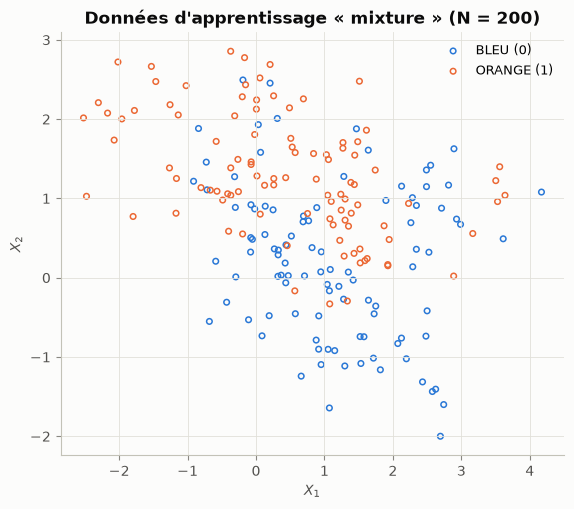

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for c, col, name in [(0, BLUE, "BLEU (0)"), (1, ORANGE, "ORANGE (1)")]:
    ax.scatter(X[g == c, 0], X[g == c, 1], s=16, facecolors="none", edgecolors=col,
               linewidths=1.1, label=name)
ax.set_xlabel("$X_1$")
ax.set_ylabel("$X_2$")
ax.set_title("Données d'apprentissage « mixture » (N = 200)")
ax.legend()
plt.show()

Les deux classes se chevauchent largement : aucune règle ne pourra les séparer
parfaitement. Ajustons le modèle linéaire avec notre fonction `least_squares_fit`
(qui résout les équations normales).

In [4]:
beta = c2.linear_classifier_fit(X, g)
print("beta_hat =", np.round(beta, 4))
A = c2.add_intercept(X)
print("vérification (2.6) :", np.allclose(beta, np.linalg.solve(A.T @ A, A.T @ g)))
print("équations normales X^T(y - X beta) =", np.round(A.T @ (g - A @ beta), 10))

beta_hat = [ 0.3291 -0.0226  0.2496]
vérification (2.6) : True
équations normales X^T(y - X beta) = [-0. -0. -0.]


Préparons une grille fine du plan pour représenter les régions de décision.

In [5]:
xlim, ylim = (-2.6, 4.2), (-2.0, 2.9)
xx, yy, grid = decision_grid(xlim, ylim, n=250)
lin_score = c2.least_squares_predict(grid, beta).reshape(xx.shape)

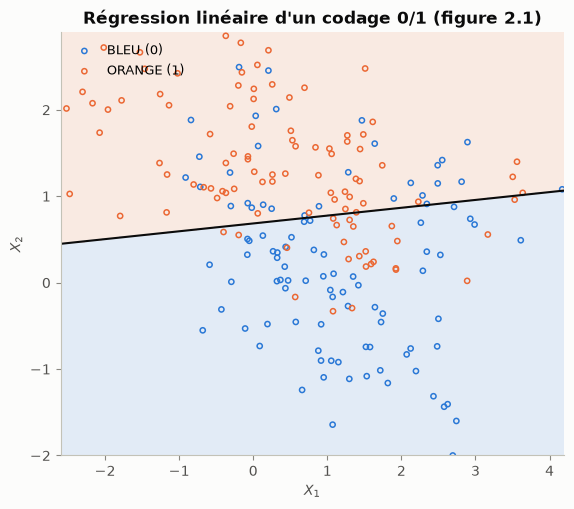

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
c2.plot_two_class(ax, X, g, xx, yy, lin_score, title="Régression linéaire d'un codage 0/1 (figure 2.1)")
ax.legend(loc="upper left")
plt.show()

In [7]:
err_lin_train = c2.error_rate(g, c2.linear_classifier_predict(X, beta))
print("Erreur d'apprentissage du modèle linéaire : %.3f" % err_lin_train)

Erreur d'apprentissage du modèle linéaire : 0.270


La frontière linéaire laisse de nombreux points du mauvais côté (environ 27 % des
points d'apprentissage). Est-ce parce que le modèle est trop rigide, ou parce que les
classes se chevauchent de toute façon ? Le livre envisage deux scénarios :

- **Scénario 1** : chaque classe suit une loi gaussienne bivariée à composantes non
  corrélées, de moyennes différentes. Une frontière linéaire est alors (quasi) optimale
  (chapitre 4).
- **Scénario 2** : chaque classe est un **mélange** de 10 gaussiennes peu dispersées,
  de centres eux-mêmes aléatoires. La frontière optimale est alors non linéaire et
  tourmentée.

## 3. Les $k$ plus proches voisins (section 2.3.2)

La méthode des $k$ plus proches voisins forme $\hat Y$ à partir des observations
d'apprentissage les plus proches de $x$ :
$$\hat Y(x) = \frac1k \sum_{x_i \in N_k(x)} y_i \qquad \text{(éq. (2.8))},$$
où $N_k(x)$ est le **voisinage** de $x$ formé des $k$ points $x_i$ les plus proches de
$x$ (ici, pour la distance euclidienne).

Avec le codage 0/1, $\hat Y(x)$ est la **proportion** de voisins ORANGE ; la règle
« ORANGE si $\hat Y(x) > 0{,}5$ » est un **vote majoritaire**.

Notre implémentation (`c2.knn_regress`) calcule la matrice des distances au carré
grâce à l'identité $\|a - b\|^2 = \|a\|^2 + \|b\|^2 - 2a^Tb$, puis trie chaque ligne.
Vérifions-la sur un petit exemple contre scikit-learn.

In [8]:
from sklearn.neighbors import KNeighborsClassifier

ref = KNeighborsClassifier(n_neighbors=15).fit(X, g).predict(grid[::97])
mine = (c2.knn_regress(X, g, grid[::97], 15) > 0.5).astype(int)
print("accord avec scikit-learn :", np.mean(ref == mine))

accord avec scikit-learn : 1.0


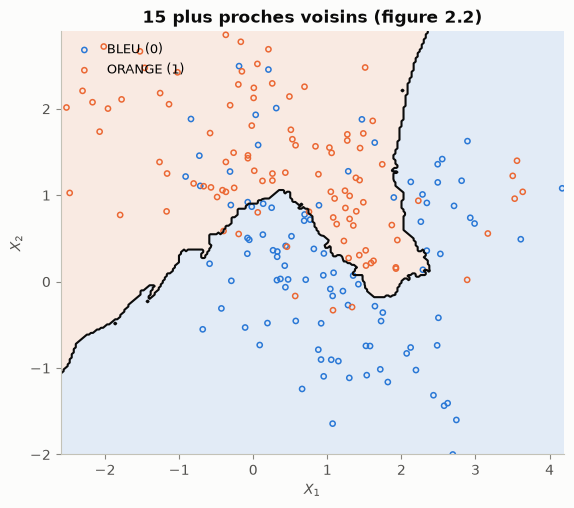

In [9]:
knn15_score = c2.knn_regress(X, g, grid, 15).reshape(xx.shape)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
c2.plot_two_class(ax, X, g, xx, yy, knn15_score, title="15 plus proches voisins (figure 2.2)")
ax.legend(loc="upper left")
plt.show()

La frontière est maintenant irrégulière et s'adapte aux amas locaux. Diminuons $k$
jusqu'à $k = 1$ : chaque point $x$ reçoit la classe de **son** plus proche voisin.

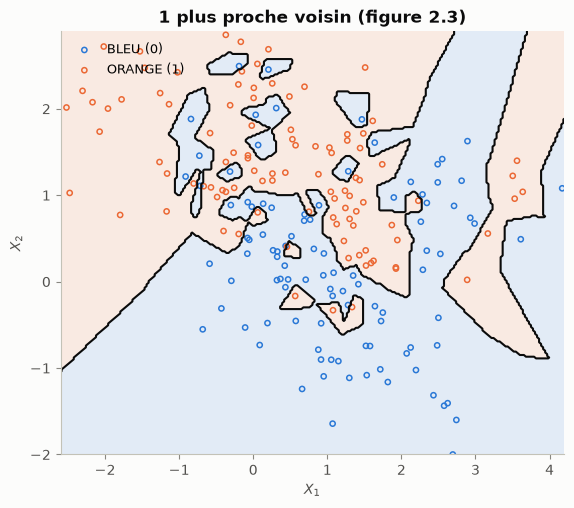

In [10]:
knn1_score = c2.knn_regress(X, g, grid, 1).reshape(xx.shape)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
c2.plot_two_class(ax, X, g, xx, yy, knn1_score, title="1 plus proche voisin (figure 2.3)")
ax.legend(loc="upper left")
plt.show()

Avec $k = 1$, le plan est découpé en **cellules de Voronoï** (l'ensemble des points plus
proches de $x_i$ que de tout autre point d'apprentissage), chacune coloriée selon la
classe de son centre. Comparons les erreurs d'apprentissage.

In [11]:
for k in (1, 15):
    err = c2.error_rate(g, c2.knn_classify(X, g, X, k))
    print("k = %2d : erreur d'apprentissage = %.3f" % (k, err))
print("linéaire : erreur d'apprentissage = %.3f" % err_lin_train)

k =  1 : erreur d'apprentissage = 0.000
k = 15 : erreur d'apprentissage = 0.155
linéaire : erreur d'apprentissage = 0.270


> **Remarque.** Avec $k = 1$, l'erreur d'apprentissage est **nulle** : chaque point
> d'apprentissage est son propre plus proche voisin. Cela ne dit rien de la qualité des
> prédictions sur de **nouvelles** données. L'erreur d'apprentissage n'est donc pas un
> bon critère pour choisir $k$ (elle choisirait toujours $k = 1$).

**Nombre effectif de paramètres.** Les $k$-ppv semblent n'avoir qu'un paramètre, $k$,
contre $p + 1 = 3$ pour le modèle linéaire. Mais si les voisinages étaient disjoints,
il y en aurait $N/k$, et l'on ajusterait une moyenne dans chacun : le **nombre effectif
de paramètres** des $k$-ppv est $N/k$, qui croît quand $k$ diminue. Avec $N = 200$ et
$k = 15$, cela fait environ 13 paramètres, bien plus que 3.

## 4. Révélation de l'oracle : comment les données ont été simulées

Les données suivent en fait un modèle proche du scénario 2 :

1. on tire 10 centres $m_1, \dots, m_{10}$ selon $\mathcal N((1, 0)^T, \mathbf I)$ pour
   la classe BLEU, et 10 centres selon $\mathcal N((0, 1)^T, \mathbf I)$ pour ORANGE ;
2. pour chaque observation d'une classe, on choisit un centre $m_k$ de cette classe
   avec probabilité $1/10$, puis on tire $x \sim \mathcal N(m_k, \mathbf I/5)$.

Chaque classe est donc un **mélange de 10 gaussiennes** de variance $1/5$.

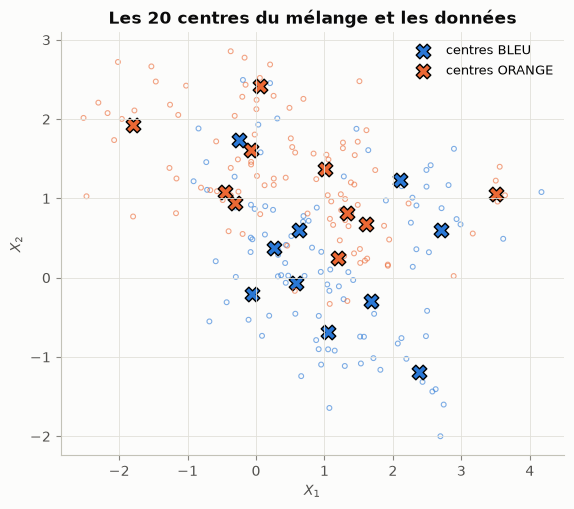

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for c, col, name in [(0, BLUE, "BLEU"), (1, ORANGE, "ORANGE")]:
    ax.scatter(X[g == c, 0], X[g == c, 1], s=12, facecolors="none", edgecolors=col,
               linewidths=0.8, alpha=0.6)
    M = means[10 * c:10 * (c + 1)]
    ax.scatter(M[:, 0], M[:, 1], s=110, marker="X", color=col, edgecolors="k",
               label="centres %s" % name)
ax.set_xlabel("$X_1$")
ax.set_ylabel("$X_2$")
ax.set_title("Les 20 centres du mélange et les données")
ax.legend()
plt.show()

Connaissant le modèle, on peut simuler un grand **échantillon test** de 10 000 points
(5 000 par classe), indépendant de l'échantillon d'apprentissage, avec les mêmes
centres. Il permet d'estimer précisément l'erreur de prédiction de chaque méthode.

In [13]:
X_test, g_test = c2.sample_mixture(means, 5000, rng)
print(X_test.shape)

(10000, 2)


## 5. Le classifieur de Bayes (figure 2.5)

Puisque nous connaissons les densités des deux classes, nous pouvons calculer la
meilleure règle possible. Notons $\varphi_{m}(x)$ la densité de $\mathcal N(m, \mathbf I/5)$
dans $\mathbb R^2$ :
$$\varphi_m(x) = \frac{5}{2\pi}\exp\Big(-\frac52\|x - m\|^2\Big).$$
La densité de la classe BLEU est $p_0(x) = \frac1{10}\sum_{k=1}^{10}\varphi_{m_k^{B}}(x)$,
celle de ORANGE $p_1(x) = \frac1{10}\sum_{k=1}^{10}\varphi_{m_k^{O}}(x)$.

Les deux classes ont la même probabilité a priori $1/2$. Par la **formule de Bayes**,
$$P(G = \text{ORANGE} \mid X = x) = \frac{\tfrac12 p_1(x)}{\tfrac12 p_0(x) + \tfrac12 p_1(x)} = \frac{p_1(x)}{p_0(x) + p_1(x)}.$$
Le **classifieur de Bayes** choisit la classe la plus probable sachant $x$ (nous
montrerons au cours 2 qu'il minimise la probabilité d'erreur) : ORANGE si
$P(\text{ORANGE} \mid x) > 1/2$, c'est-à-dire si $p_1(x) > p_0(x)$.

In [14]:
bayes_grid = c2.bayes_posterior(grid, means).reshape(xx.shape)
print("écart max avec les probabilités fournies par le livre :",
      np.abs(c2.bayes_posterior(mix["xnew"], means) - mix["prob"]).max())

écart max avec les probabilités fournies par le livre : 4.218847493575595e-15


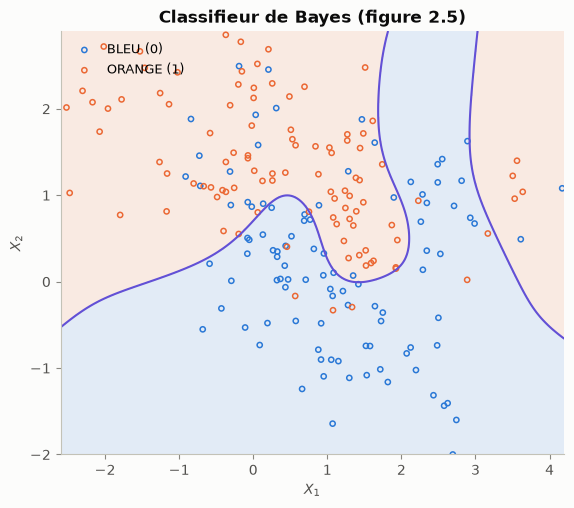

In [15]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
c2.plot_two_class(ax, X, g, xx, yy, bayes_grid, boundary_color=COLORS[6],
                  title="Classifieur de Bayes (figure 2.5)")
ax.legend(loc="upper left")
plt.show()

Le **taux d'erreur de Bayes** est l'erreur de cette règle optimale. Estimons-le sur
l'échantillon test.

In [16]:
err_bayes = c2.error_rate(g_test, c2.bayes_classify(X_test, means))
print("Erreur de Bayes estimée : %.3f" % err_bayes)

Erreur de Bayes estimée : 0.210


Environ 21 % : même la règle optimale se trompe souvent, car les classes se
chevauchent. Aucune méthode ne peut faire mieux **en moyenne**. Superposons les quatre
frontières obtenues.

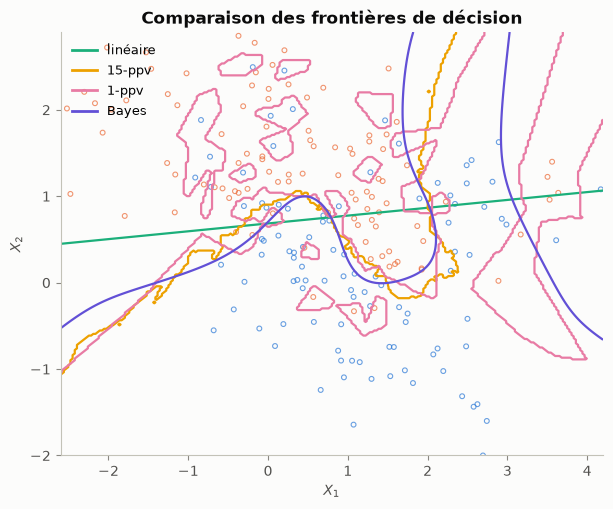

In [17]:
fig, ax = plt.subplots(figsize=(7, 5.5))
for c, col in [(0, BLUE), (1, ORANGE)]:
    ax.scatter(X[g == c, 0], X[g == c, 1], s=12, facecolors="none", edgecolors=col,
               linewidths=0.8, alpha=0.7)
handles = []
for score, col, name in [(lin_score, COLORS[2], "linéaire"), (knn15_score, COLORS[3], "15-ppv"),
                         (knn1_score, COLORS[4], "1-ppv"), (bayes_grid, COLORS[6], "Bayes")]:
    cs = ax.contour(xx, yy, score, levels=[0.5], colors=col, linewidths=1.6)
    handles.append(plt.Line2D([], [], color=col, label=name))
ax.legend(handles=handles, loc="upper left")
ax.set_xlabel("$X_1$")
ax.set_ylabel("$X_2$")
ax.grid(False)
ax.set_title("Comparaison des frontières de décision")
plt.show()

## 6. Erreurs d'apprentissage et de test en fonction de $k$ (figure 2.4)

Calculons, pour une gamme de valeurs de $k$ (de 151 à 1), l'erreur d'apprentissage
et l'erreur sur l'échantillon test, et plaçons-les en fonction du nombre effectif de
paramètres $N/k$.

In [18]:
ks = np.array([151, 101, 69, 45, 31, 21, 11, 7, 5, 3, 1])
err_train = np.array([c2.error_rate(g, c2.knn_classify(X, g, X, k)) for k in ks])
err_test = np.array([c2.error_rate(g_test, c2.knn_classify(X, g, X_test, k)) for k in ks])
err_lin_test = c2.error_rate(g_test, c2.linear_classifier_predict(X_test, beta))
for k, a, b in zip(ks, err_train, err_test):
    print("k = %3d   N/k = %6.1f   apprentissage = %.3f   test = %.3f" % (k, 200 / k, a, b))
print("linéaire (3 ddl)  apprentissage = %.3f   test = %.3f" % (err_lin_train, err_lin_test))

k = 151   N/k =    1.3   apprentissage = 0.305   test = 0.332
k = 101   N/k =    2.0   apprentissage = 0.305   test = 0.310
k =  69   N/k =    2.9   apprentissage = 0.250   test = 0.283
k =  45   N/k =    4.4   apprentissage = 0.210   test = 0.266
k =  31   N/k =    6.5   apprentissage = 0.180   test = 0.258
k =  21   N/k =    9.5   apprentissage = 0.175   test = 0.252
k =  11   N/k =   18.2   apprentissage = 0.185   test = 0.248
k =   7   N/k =   28.6   apprentissage = 0.145   test = 0.225
k =   5   N/k =   40.0   apprentissage = 0.130   test = 0.231
k =   3   N/k =   66.7   apprentissage = 0.130   test = 0.243
k =   1   N/k =  200.0   apprentissage = 0.000   test = 0.296
linéaire (3 ddl)  apprentissage = 0.270   test = 0.285


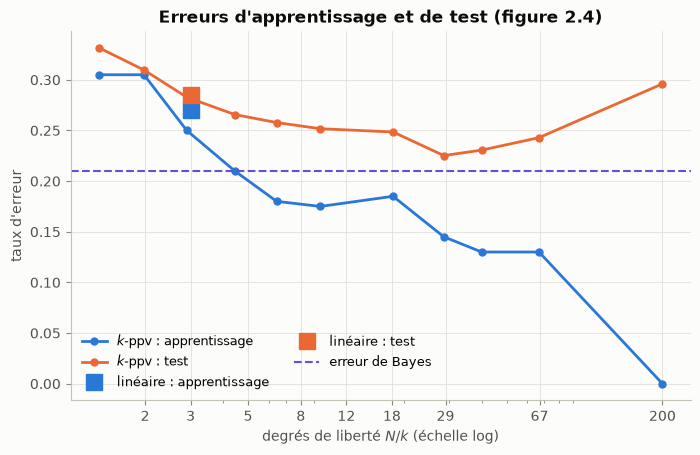

In [19]:
dof = 200 / ks
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(dof, err_train, "o-", color=BLUE, label="$k$-ppv : apprentissage")
ax.plot(dof, err_test, "o-", color=ORANGE, label="$k$-ppv : test")
ax.plot([3], [err_lin_train], "s", ms=11, color=BLUE, label="linéaire : apprentissage")
ax.plot([3], [err_lin_test], "s", ms=11, color=ORANGE, label="linéaire : test")
ax.axhline(err_bayes, color=COLORS[6], lw=1.5, ls="--", label="erreur de Bayes")
ax.set_xscale("log")
ax.set_xticks([2, 3, 5, 8, 12, 18, 29, 67, 200])
ax.set_xticklabels(["2", "3", "5", "8", "12", "18", "29", "67", "200"])
ax.set_xlabel("degrés de liberté $N/k$ (échelle log)")
ax.set_ylabel("taux d'erreur")
ax.set_title("Erreurs d'apprentissage et de test (figure 2.4)")
ax.legend(ncol=2)
plt.show()

Lecture de la figure :

- l'erreur d'**apprentissage** des $k$-ppv décroît quand la complexité $N/k$ augmente,
  jusqu'à 0 pour $k = 1$ ;
- l'erreur de **test** décroît d'abord puis **remonte** pour les petits $k$ : le modèle
  « apprend le bruit » des données d'apprentissage (sur-apprentissage) ;
- le minimum de l'erreur test est atteint pour un $k$ intermédiaire, assez proche de
  l'erreur de Bayes ; le modèle linéaire, trop rigide ici, fait nettement moins bien.

## 7. Stabilité : biais faible ou variance faible ?

La frontière linéaire est **lisse et stable**, mais repose fortement sur l'hypothèse
de linéarité : on dira qu'elle a une **variance faible** et un **biais potentiellement
élevé**. La frontière des 1-ppv dépend de quelques points et de leurs positions
exactes : **variance élevée**, **biais faible**.

Visualisons-le en simulant trois échantillons d'apprentissage indépendants (mêmes
centres) et en superposant les frontières obtenues.

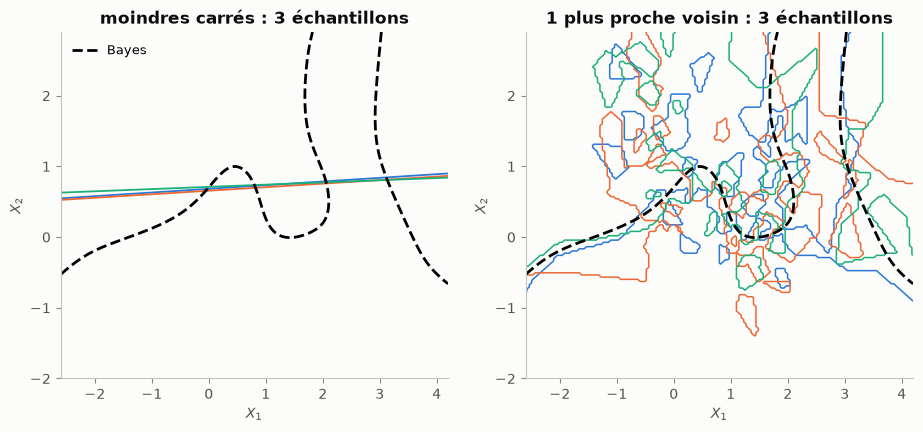

In [20]:
xs, ys, gs = decision_grid(xlim, ylim, n=160)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for r in range(3):
    Xr, gr = c2.sample_mixture(means, 100, rng)
    s_lin = c2.least_squares_predict(gs, c2.linear_classifier_fit(Xr, gr)).reshape(xs.shape)
    s_nn = c2.knn_regress(Xr, gr, gs, 1).reshape(xs.shape)
    axes[0].contour(xs, ys, s_lin, levels=[0.5], colors=[COLORS[r]], linewidths=1.3)
    axes[1].contour(xs, ys, s_nn, levels=[0.5], colors=[COLORS[r]], linewidths=1.1)
for ax, name in zip(axes, ["moindres carrés", "1 plus proche voisin"]):
    ax.contour(xx, yy, bayes_grid, levels=[0.5], colors="k", linewidths=2, linestyles="--")
    ax.set_title("%s : 3 échantillons" % name)
    ax.set_xlabel("$X_1$")
    ax.set_ylabel("$X_2$")
    ax.grid(False)
axes[0].plot([], [], "k--", label="Bayes")
axes[0].legend(loc="upper left")
plt.show()

Les droites (à gauche) varient peu d'un échantillon à l'autre mais restent loin de la
frontière de Bayes (en pointillés) ; les frontières des 1-ppv (à droite) suivent en
moyenne la frontière de Bayes, mais changent énormément d'un échantillon à l'autre.

**Variantes.** Une grande partie des méthodes modernes sont des raffinements de ces deux
procédures : noyaux dont les poids décroissent continûment avec la distance (au lieu
des poids 0/1 des $k$-ppv), distances qui privilégient certaines variables, régression
linéaire locale, développements sur des bases de fonctions, réseaux de neurones…

## 8. Bilan

> **À retenir.**
> - Moindres carrés : $\hat\beta = (\mathbf X^T\mathbf X)^{-1}\mathbf X^T\mathbf y$ ; frontière
>   linéaire, stable (variance faible) mais potentiellement biaisée.
> - $k$-ppv : moyenne locale $\frac1k\sum_{x_i\in N_k(x)} y_i$ ; flexible (biais faible),
>   instable (variance élevée) quand $k$ est petit ; nombre effectif de paramètres $N/k$.
> - L'erreur d'apprentissage sous-estime l'erreur de prédiction et ne permet pas de
>   choisir la complexité ; il faut un échantillon test (ou une validation, chapitre 7).
> - Le classifieur de Bayes, $\hat G(x) = \arg\max_g P(g \mid x)$, est la référence
>   optimale ; ici son erreur vaut environ 21 %.